# 오탐률 유지 조건의 F1·Recall 개선 실험

목표는 직전 release 대비 **두 지표 모두 +10~20%p**. 아래에서 목표 달성 여부와 실제 채택 여부를 구분한다. 기존 데이터·정답·기존 모델을 수정하지 않았다.

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]if(p/'reports/shared_model_v2_release/summary.json').exists())
OUT=ROOT/'reports/shared_model_v3_release'
read=lambda p:json.loads(p.read_text(encoding='utf-8'))
result=read(OUT/'summary.json'); adoption=read(OUT/'adoption.json')
def metrics(rows):
    return(pd.DataFrame(rows).set_index('method')[['accuracy','precision','recall','f1','normal_false_positive_rate']]*100).round(2)

## 1. 전체 전후 비교

동일 **2,167,766개 1분 판정**, 정상 1,785,918 / 이상 381,848. 오탐률=FP/(TN+FP). 이상 사례 속 정상 배경과 정상 대조군을 모두 포함한다. point adjustment 없음. 목표 미달이면 미달로 표시한다.

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,87.87,76.25,45.25,56.79,3.01
kmeans,88.76,82.71,45.77,58.93,2.05
lof,87.85,79.01,42.25,55.06,2.40


,method,F1_gain_pp,recall_gain_pp,FPR_gain_pp,FPR_no_increase,target_plus_10pp_met
0,if,1.788013,1.718223,-0.139088,True,False
1,kmeans,2.708719,2.640318,-0.156558,True,False
2,lof,0.000000,0.000000,0.000000,True,False


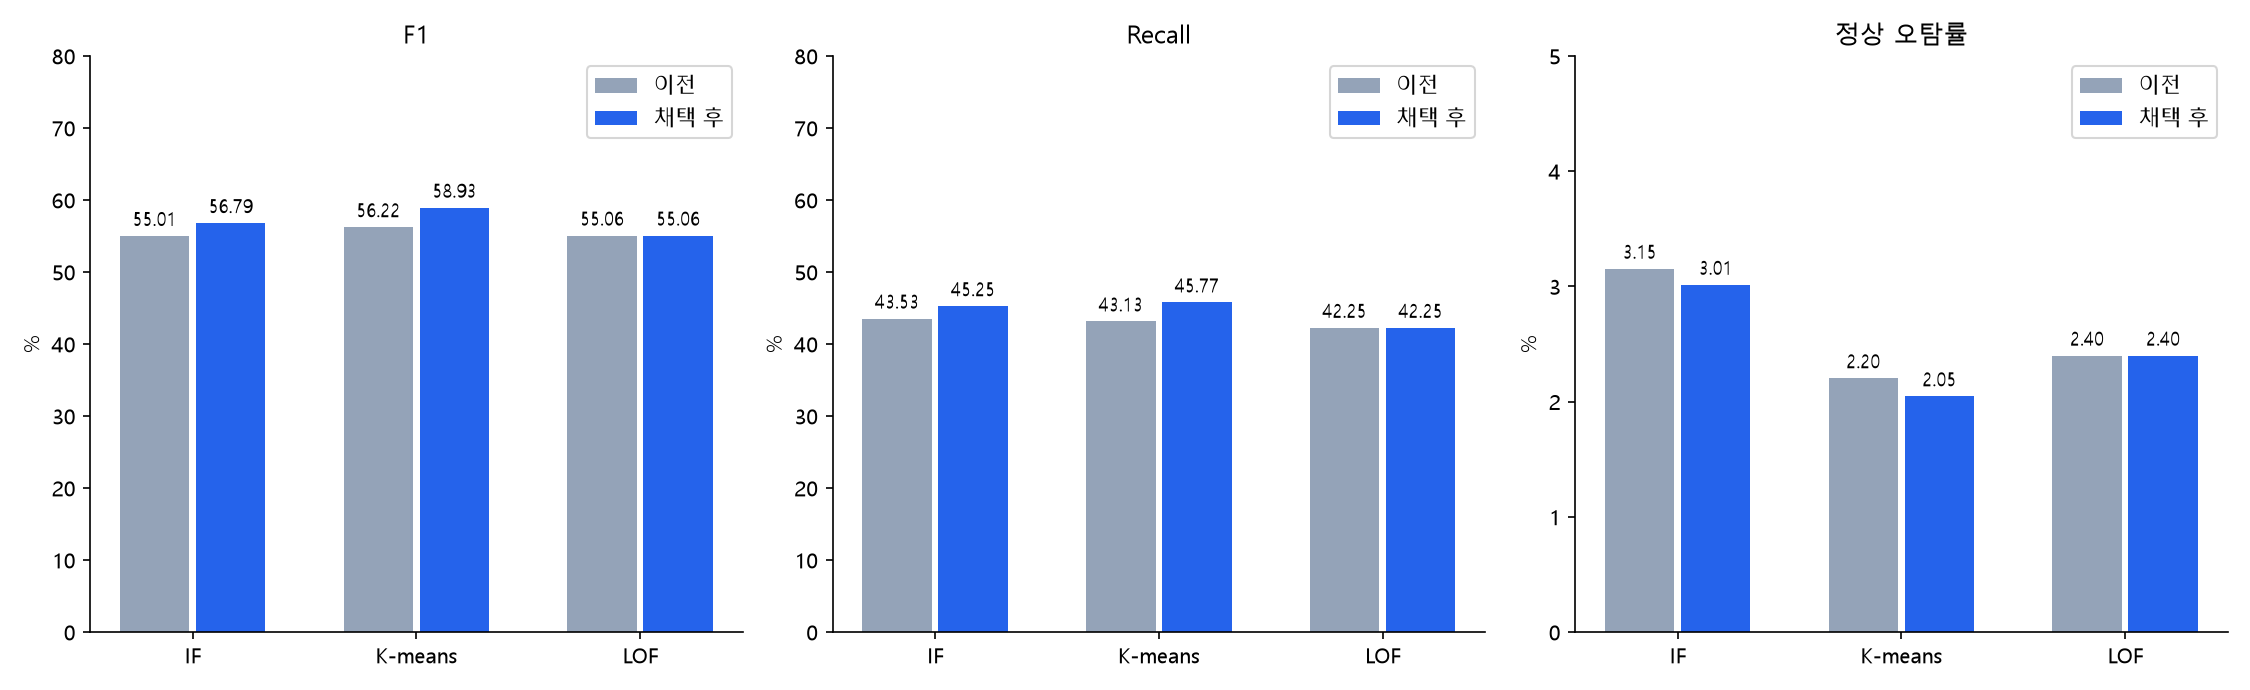

In [2]:
display(metrics(result['pooled']))
display(pd.DataFrame(result['changes']))
display(Image(filename=str(OUT/'figures/comparison.png')))

## 2. 무엇을 실제로 비교했나

1. **시간 표현**: 현재 소요시간의 초기 관측 대비 변화, 누적 지연·EWMA, 관측 간격에 맞춘 짧은 기억, 실행 횟수의 과산포를 고려한 변화.
2. **작은 지연**: 거의 일정한 스트림에서 기존 log 소요시간 최소 변동폭 0.15보다 작은 0.03/잔차 0.05 바닥을 비교. 작게 잡으면 민감해지지만 자연 변동도 이상처럼 보일 수 있다.
3. **정상 분포 표현**: 정상 train의 고정 CDF·꼬리 요약과 피처 구성/가중치 비교. 문자열 ID는 숫자로 넣지 않았다.
4. **알고리즘 기하**: IF 표본 수·피처 부분선택, K-means 군집 반경 보정의 강도, LOF의 Manhattan/Chebyshev/Cosine 거리와 이웃 수.
5. **경보 점수**: 정상 점수의 Adapter·관측 상태 보정, 과거 점수 누적/기억. 정답 이벤트의 시작·끝은 사용하지 않는다.

탐지기 학습은 정상 후보만 사용했지만 **하이퍼파라미터 선택에는 개발 라벨을 사용**했다. 피처/경보선 변경을 모두 순수 Adapter 피처 효과라고 해석하면 안 된다. 정상 S 역시 성능 정상의 보증은 아니다.

In [3]:
manifest=read(OUT/'handoff/manifest.json'); selection=read(OUT/'selection.json')
for r in manifest['models']:
    a=r['algorithm']; c=selection['selected'][a]
    display(Markdown('### '+a))
    display(pd.Series({'previous_retained':c['retained_previous'],'source':c['source'],'feature_count':len(r['columns']),'fit_rows':r['fit_rows'],'threshold':r['threshold'],'calibration_mode':r['calibration_mode'],'calibration_kind':r['calibration_kind'],'geometry_refit':r.get('geometry_refit'),'actual_estimator_parameters':r.get('actual_estimator_parameters',r['settings'])},name='실제 채택 설정').to_frame())

### if

,실제 채택 설정
previous_retained,False
source,reports\shared_model_v3_geometry
feature_count,26
fit_rows,19793
threshold,1.246281
calibration_mode,availability
calibration_kind,robust
geometry_refit,"{'algorithm': 'if', 'samples': 32, 'max_featur..."
actual_estimator_parameters,"{'bootstrap': False, 'contamination': 'auto', ..."


### kmeans

,실제 채택 설정
previous_retained,False
source,reports\shared_model_v3_conservative
feature_count,32
fit_rows,19595
threshold,1.456785
calibration_mode,adapter_availability
calibration_kind,robust
geometry_refit,None
actual_estimator_parameters,"{'batch_size': 2048, 'compute_labels': True, '..."


### lof

,실제 채택 설정
previous_retained,True
source,reports\shared_model_v2_release
feature_count,32
fit_rows,2048
threshold,1.865514
calibration_mode,availability
calibration_kind,robust
geometry_refit,None
actual_estimator_parameters,"{'algorithm': 'auto', 'contamination': 'auto',..."


## 3. 채택·탈락 기준

전체 평가에서 **FP 증가 없음 + F1·Recall 모두 상승**인 후보만 채택. 하나라도 만족하지 못하면 이전 모델 유지. **각 후보는 전수 평가 전에 경보선을 동결**했다. 앞선 K-means 후보의 오탐 초과를 본 뒤, 다음 후보 하나는 별도 정상 calibration 점수의 **P99.5**라는 보수적인 정책으로 고정했다. 전수 평가 FPR을 맞추도록 cutoff를 역산하지는 않았다.

앞선 결과를 보며 피처/정책을 다시 설계하고 평가한 반복 연구이다. 외부 블라인드 성능이 아니며, 기존 평가를 이용한 채택 자체에도 선택 편향이 있다.

In [4]:
display(pd.DataFrame(adoption['attempts'])[['method','source','eligible','F1_gain_pp','recall_gain_pp','FPR_gain_pp']])
display(pd.Series(adoption['chosen'],name='채택 출처').to_frame())

,method,source,eligible,F1_gain_pp,recall_gain_pp,FPR_gain_pp
0,if,reports\shared_model_v3_candidate1,False,-2.197558,-0.537125,1.088180
1,if,reports\shared_model_v3_calibration,False,-2.197558,-0.537125,1.088180
2,if,reports\shared_model_v3_geometry,True,1.788013,1.718223,-0.139088
3,if,reports\shared_model_v3_conservative,False,0.000000,0.000000,0.000000
4,kmeans,reports\shared_model_v3_candidate1,False,4.471007,6.320316,0.684970
5,kmeans,reports\shared_model_v3_calibration,False,4.030935,5.315728,0.441286
6,kmeans,reports\shared_model_v3_geometry,False,0.000000,0.000000,0.000000
7,kmeans,reports\shared_model_v3_conservative,True,2.708719,2.640318,-0.156558
8,lof,reports\shared_model_v3_candidate1,False,0.000000,0.000000,0.000000
9,lof,reports\shared_model_v3_calibration,False,0.000000,0.000000,0.000000


,채택 출처
if,reports\shared_model_v3_geometry
kmeans,reports\shared_model_v3_conservative
lof,reports\shared_model_v2_release


## 4. 시나리오별 결과

전체 개선이 모든 시나리오의 개선을 뜻하지 않는다. 개별·집단 지연, 컬럼 관계, 폭주, 중단, 점진적 악화, Hard를 모두 유지했다.

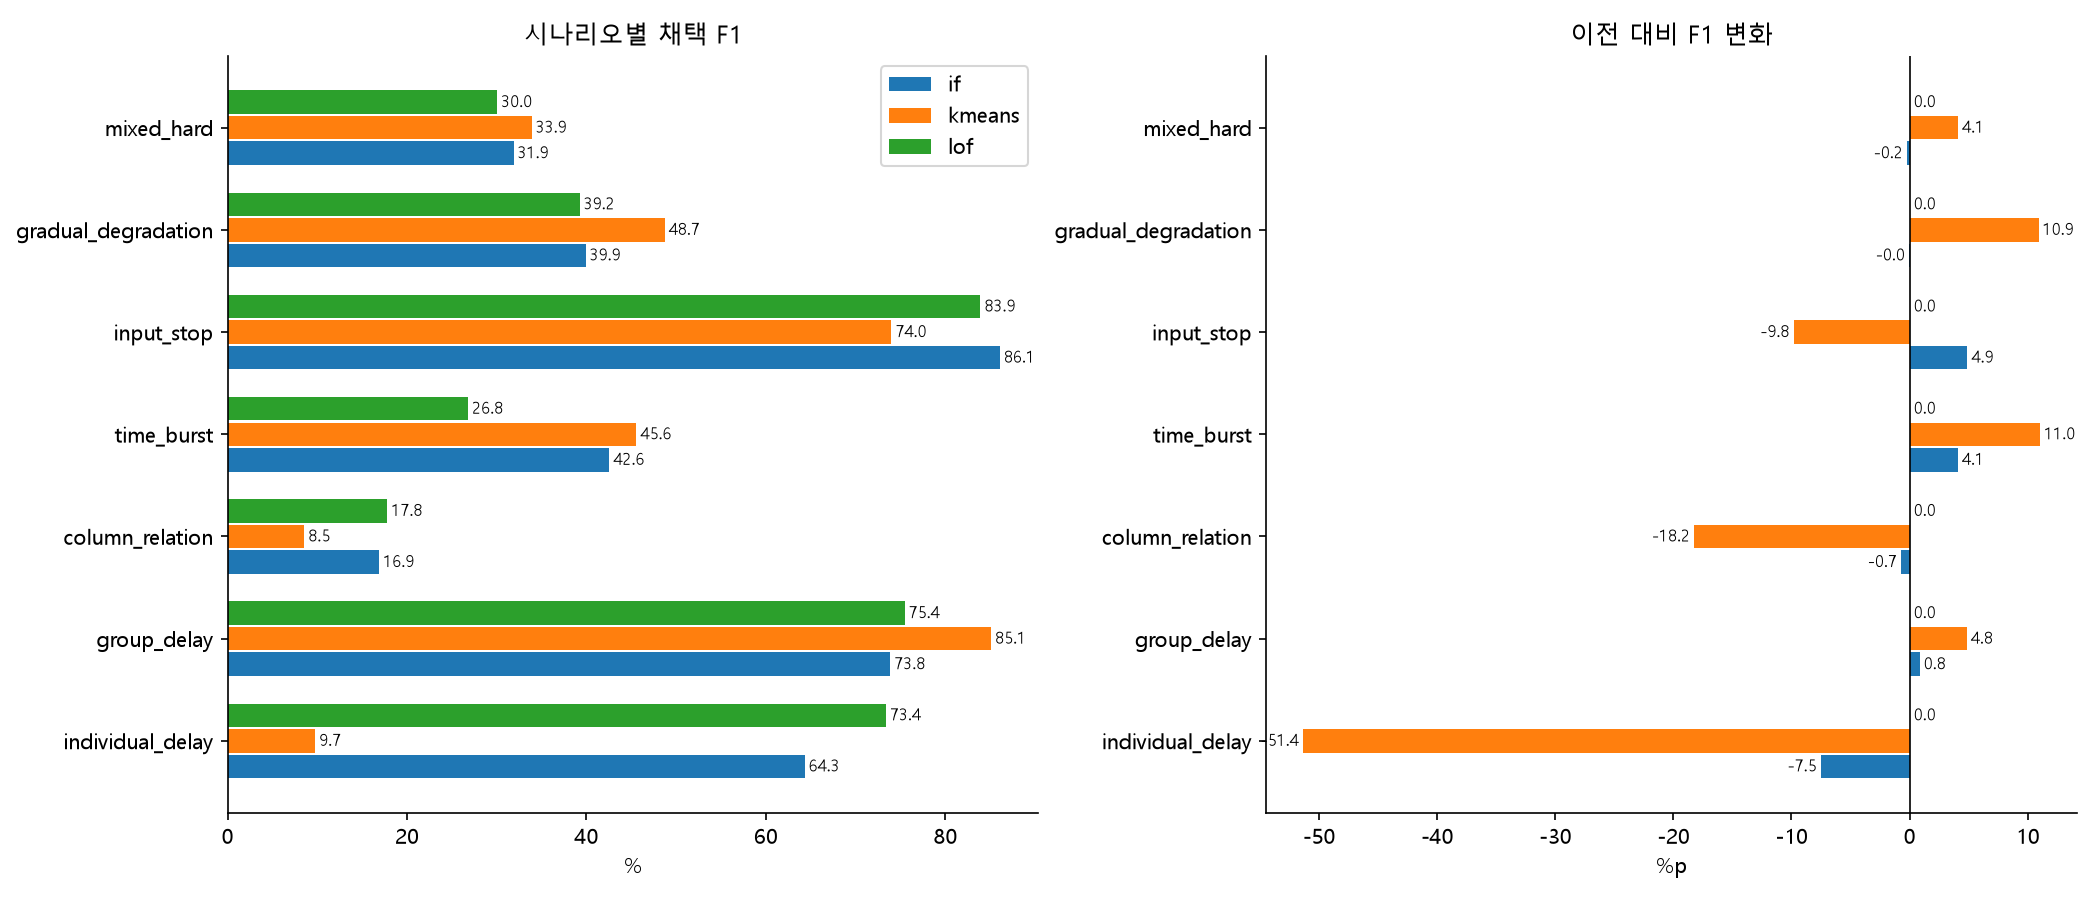

### individual_delay

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,95.08,83.79,52.17,64.30,0.94
kmeans,91.94,99.62,5.12,9.75,0.00
lof,96.33,95.62,59.51,73.36,0.25


### group_delay

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,92.11,74.16,73.53,73.85,4.57
kmeans,95.08,78.74,92.55,85.08,4.46
lof,92.73,77.22,73.75,75.45,3.88


### column_relation

...

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,95.88,93.08,80.05,86.07,1.13
kmeans,93.27,96.16,60.12,73.99,0.45
lof,95.38,94.11,75.69,83.90,0.90


### gradual_degradation

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,78.5,65.53,28.68,39.89,5.00
kmeans,81.6,79.46,35.13,48.72,3.01
lof,78.7,67.64,27.63,39.23,4.38


### mixed_hard

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,79.94,65.20,21.09,31.87,3.22
kmeans,80.85,73.03,22.06,33.88,2.33
lof,80.28,71.27,19.02,30.03,2.19


In [5]:
display(Image(filename=str(OUT/'figures/scenarios.png')))
for d in result['datasets']:
    display(Markdown('### '+d['dataset'])); display(metrics(d['metrics']))

## 5. 점수 분포와 경보선

일반 막대 히스토그램. 점선보다 높은 점수가 경보이며 표시 밖 꼬리도 실제 평가에는 전부 포함했다. 모델 간 점수 크기는 직접 비교하지 않는다.

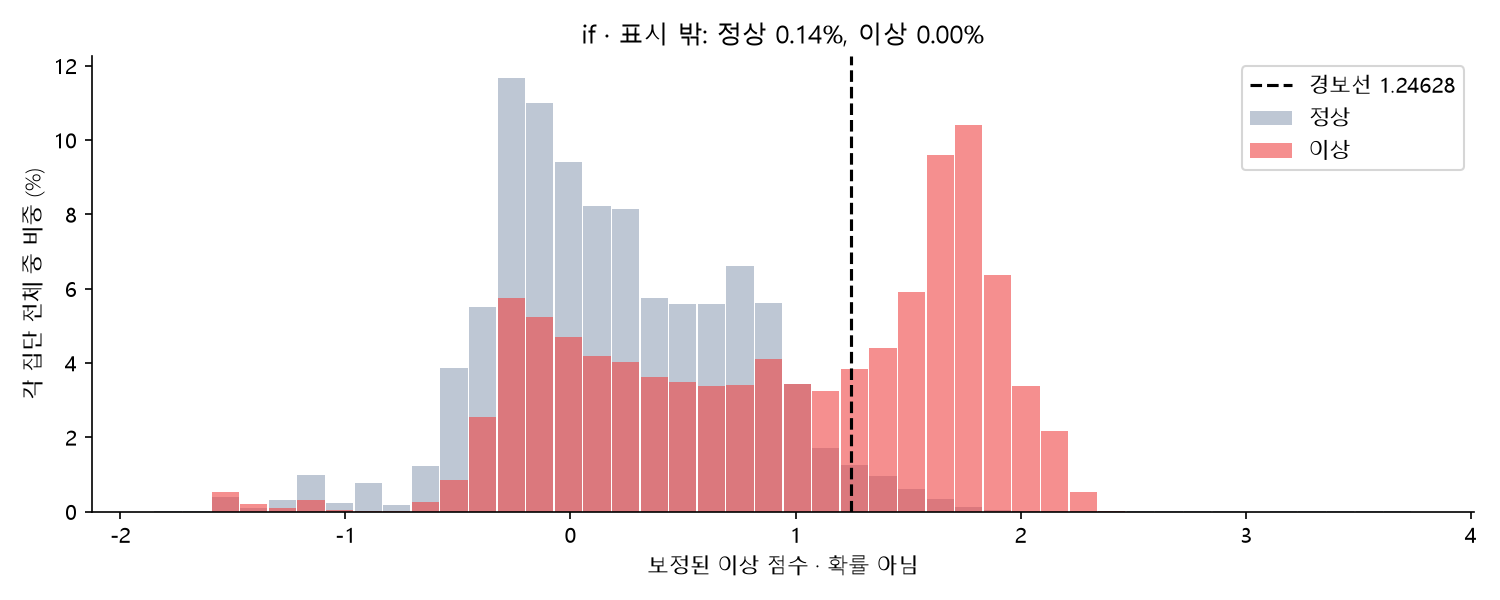

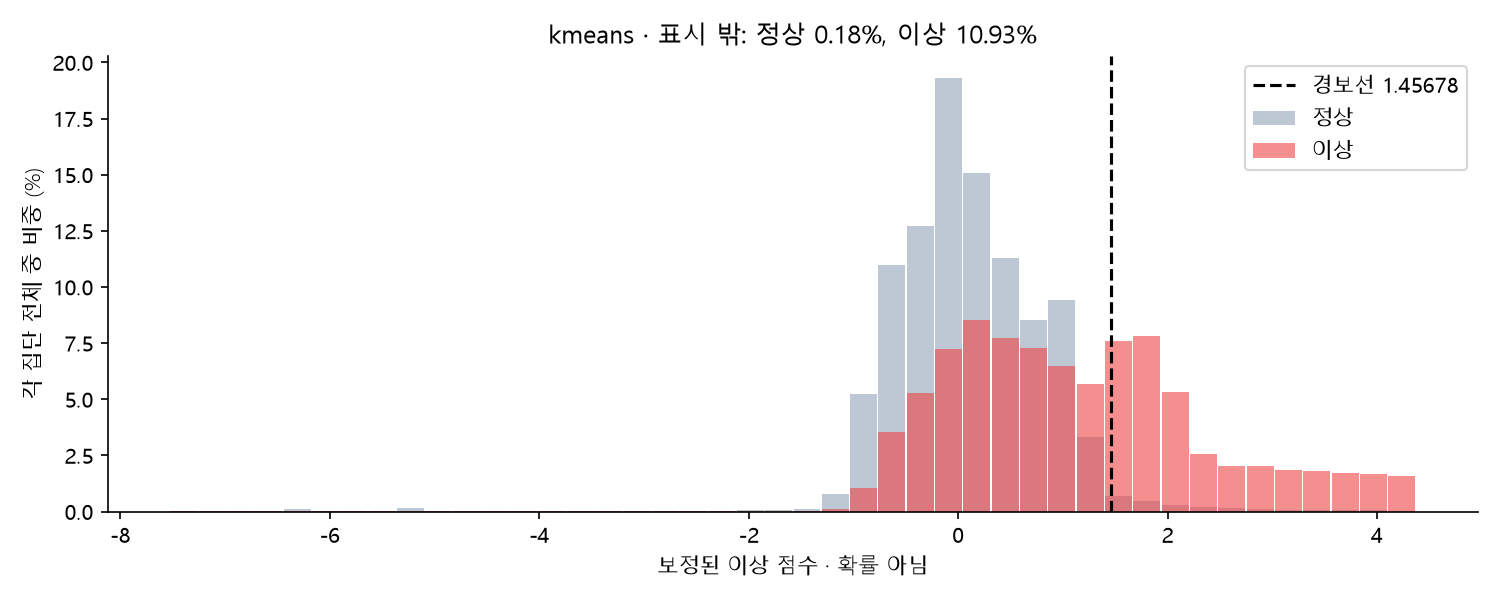

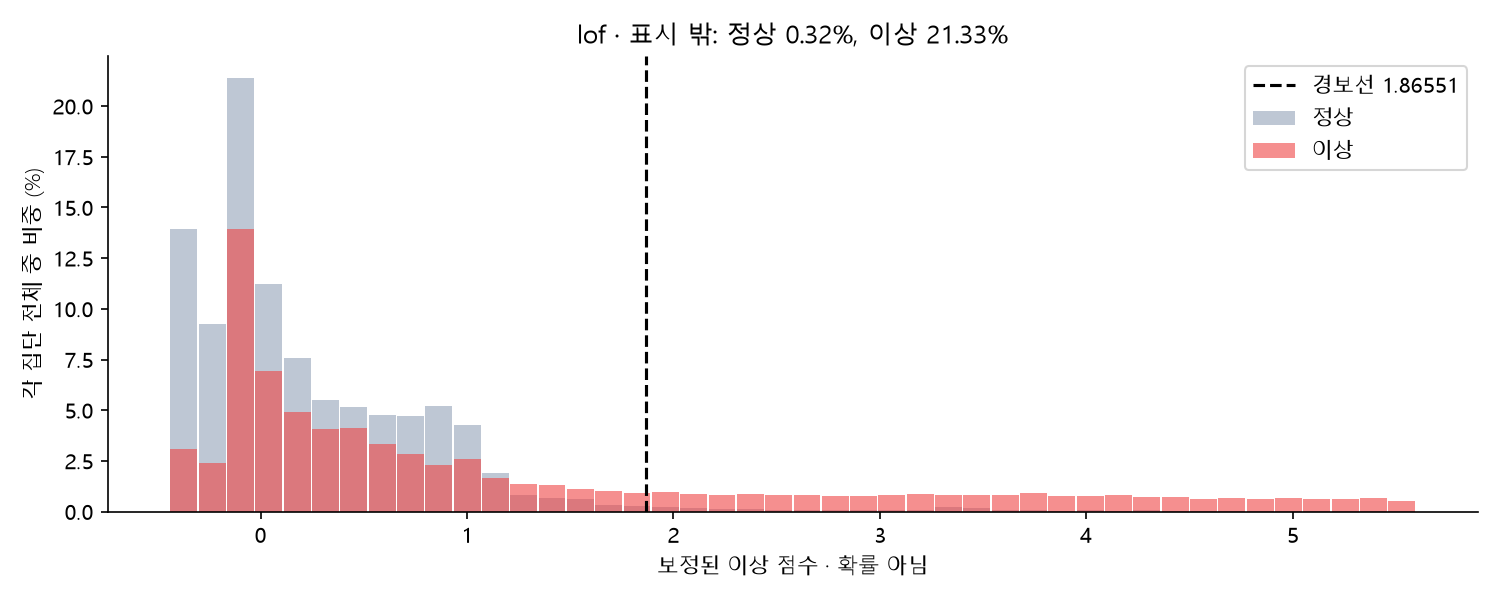

In [6]:
for a in ['if','kmeans','lof']:display(Image(filename=str(OUT/'figures'/f'{a}_threshold.png')))

## 6. 관측 한계와 실험에서 제외한 것

개발 쌍을 비교했을 때 컬럼 관계 이상의 50%, 점진적 악화의 약 10%는 이 실험의 숫자 피처가 정상 대조군과 같았다. 해당 분에 새 완료가 없거나 아직 변화가 관측되지 않은 경우가 있다. **원시 로그의 다른 정보까지 없다는 이론적 불가능 증명은 아니다.**

과거 개발 정상 대조군의 시작/완료 행 수 일부가 별도로 재집계되지 않은 것을 발견해, 이 두 필드를 쓰는 **flow=True 후보는 최종 선택에서 제외**했다. 기존 release 모델은 해당 필드를 피처로 쓰지 않는다. 오류를 모델 성능 향상처럼 이용하지 않았다.

ADBench 기존 1,000개는 독립 숫자 피처 표라서 새 시간 피처를 계산할 실제 이력이 없다. 없는 시간 정보를 만들어 재평가하지 않았다. 이번 결과는 원래 Process 시나리오 벤치마크 기준이다.

In [7]:
display(pd.DataFrame(read(ROOT/'reports/shared_model_v3/observability.json')['records']))
if(OUT/'fresh_comparison.json').exists():
    fresh=read(OUT/'fresh_comparison.json')
    display(Markdown('새 seed '+str(fresh['seed'])+' / 모델 동결 후 동일 사례로 전후 비교. 원형 생성기이며 mild-v2가 아니다. 같은 원본 pool이므로 외부 블라인드 평가가 아니고 재선택에 사용하지 않았다.'))
    for version in ['baseline','adopted']:
        display(Markdown('### 새 seed 확인 / '+version));display(metrics([r for r in fresh['rows']if r['version']==version]))
audit=read(OUT/'audit.json')
display({k:audit[k]for k in ['passed','old_models_unchanged','minute_metrics_recomputed','truth_case_alignment_unchanged','no_increase_FP_each_model','F1_and_recall_no_regression_each_model','target_plus_10pp_met','unit_tests_passed']})

,split,scenario,positive_minutes,feature_identical_to_normal_pair,identical_fraction,no_current_completion_fraction
0,search,column_relation,180,90,0.500000,0.500000
1,search,gradual_degradation,2720,281,0.103309,0.268750
2,search,group_delay,990,39,0.039394,0.254545
3,search,individual_delay,90,0,0.000000,0.000000
4,search,input_stop,1070,35,0.032710,1.000000
5,search,time_burst,776,25,0.032216,0.158505
6,confirmation,column_relation,360,180,0.500000,0.500000
7,confirmation,gradual_degradation,5400,541,0.100185,0.271667
8,confirmation,group_delay,1980,58,0.029293,0.270202
9,confirmation,individual_delay,180,0,0.000000,0.000000


새 seed 45100042 / 모델 동결 후 동일 사례로 전후 비교. 원형 생성기이며 mild-v2가 아니다. 같은 원본 pool이므로 외부 블라인드 평가가 아니고 재선택에 사용하지 않았다.

### 새 seed 확인 / baseline

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,88.47,70.90,48.07,57.30,3.78
kmeans,89.84,80.09,49.08,60.86,2.34
lof,89.39,79.08,46.35,58.45,2.35


### 새 seed 확인 / adopted

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,89.06,73.93,49.41,59.24,3.34
kmeans,89.96,82.91,47.37,60.29,1.87
lof,89.39,79.08,46.35,58.45,2.35


{'passed': True,
 'old_models_unchanged': True,
 'minute_metrics_recomputed': True,
 'truth_case_alignment_unchanged': True,
 'no_increase_FP_each_model': True,
 'F1_and_recall_no_regression_each_model': True,
 'target_plus_10pp_met': {'if': False, 'kmeans': False, 'lof': False},
 'unit_tests_passed': 53}

**새 seed 해석:** IF는 F1·Recall 개선과 오탐 감소가 함께 재현됐다. K-means는 오탐은 줄었지만 F1 **60.86→60.29%**, Recall **49.08→47.37%**로 하락했다. 따라서 K-means의 일반화 개선은 확인되지 않았다. 전수 개선 후보와 새 사례 검증 결과를 구분해야 한다. 모델을 이 확인 결과로 다시 선택하지 않았고, 연구 후보 전달이지 운영 배포 승인이 아니다.

## 7. 참고와 백엔드 적용

[CUSUM · NIST](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm)은 작은 변화의 누적 관측이라는 설계 근거이다. 여기서는 감쇠·회복 해제된 파생 피처/점수 후보로 변형했으며 논문의 정확한 알고리즘 재현이나 성능 보장은 아니다. [LOF 공식 문서](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html)의 거리·이웃·novelty 설정과 [IF 공식 문서](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)의 표본·피처 부분선택을 비교했다.

`handoff/` 모델은 동일한 Process-derived 연속 1분 grid와 완료 행 인터페이스를 사용한다. Adapter+Process별 과거 상태, 빈 분 생성, 지연 도착 처리는 backend 워커 책임이다. 운영 배포·GitHub·Notion 변경은 하지 않았다.